# One-class-SVM 알고리즘 기반 이상치 탐지 실험

- 목표: One-Class-SVM 모델의 이상치 탐지 성능을 일반적인 타 알고리즘과 비교·검증한다
- 사용 데이터: Kaggle Credit Data Set / URL: 
- 사용 알고리즘: One - Class - SVM
- 비교 알고리즘: 
- 분석 워크플로우: DataLoad -> EDA -> Data Profiling -> Data Cleansing -> Featuring -> Data Shaping -> Modeling -> Train / Test -> Conclusion 


## Import Library

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import seaborn as sns
import math
from sklearn.model_selection import train_test_split

## Direction

In [3]:
BASE_PATH = pathlib.Path().resolve().parent
DATA_PATH = BASE_PATH / "data"
RESULT_PATH = BASE_PATH / "results"

## Load Data

In [4]:
data = pd.read_csv(DATA_PATH / "creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print(data.columns)
print(data.shape)
print(data.isna().sum())
print('='*100)

display(np.round(data.describe(include='all').T, 5))
display(data.info())

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')
(284807, 31)
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.85958,47488.14595,0.00000,54201.50000,84692.00000,139320.50000,172792.00000
V1,284807.0,0.00000,1.95870,-56.40751,-0.92037,0.01811,1.31564,2.45493
V2,284807.0,0.00000,1.65131,-72.71573,-0.59855,0.06549,0.80372,22.05773
V3,284807.0,-0.00000,1.51626,-48.32559,-0.89036,0.17985,1.02720,9.38256
V4,284807.0,0.00000,1.41587,-5.68317,-0.84864,-0.01985,0.74334,16.87534
V5,284807.0,0.00000,1.38025,-113.74331,-0.69160,-0.05434,0.61193,34.80167
V6,284807.0,0.00000,1.33227,-26.16051,-0.76830,-0.27419,0.39856,73.30163
V7,284807.0,-0.00000,1.23709,-43.55724,-0.55408,0.04010,0.57044,120.58949
V8,284807.0,0.00000,1.19435,-73.21672,-0.20863,0.02236,0.32735,20.00721
V9,284807.0,-0.00000,1.09863,-13.43407,-0.64310,-0.05143,0.59714,15.59499


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

None

## Data EDA
- Data Dictionary 점검
    - V1~V28: 원래 거래 정보를 PCA로 변환한 28개의 주성분 값
    - Time: 데이터 전체의 첫 거래부터 해당 거래까지 경과한 시간. 단위는 초
    - Amount: 해당 거래의 결제 금액
    - Class: 거래의 사기 여부 정답지 (0:정상거래, 1:사기거래)

- Data Profiling
    1. 행 284,807개와 열(칼럼) 31개

    2. PCA 변수의 기초 특성
    - V1~V28의 평균은 모두 0에 근접한다. 그러나 표준편차는 V1 약 1.9587에서 V28 약 0.3301까지 차이가 있어, PCA가 적용되었더라도 변수별 분산이 동일하지는 않다.
    - 일부 변수는 중앙 구간에 비해 최솟값·최댓값이 크게 벗어나 있다. 예를 들어 V28의 가운데 50%는 약 −0.0530~0.0783에 위치하지만, 전체 범위는 약 −15.4301~33.8478로 나타났다.

    3. 거래 금액 분포
    - Amount의 평균은 88.3496, 중앙값은 22.0000이며, 거래의 75%가 77.1650 이하에 위치한다. 
    - 반면 최댓값은 25,691.1600으로, 일반적인 거래 금액에 비해 매우 크다.
    - 평균이 중앙값보다 크게 높고 상단 범위가 길게 확장되어 있어, 고액 거래가 평균과 산포에 영향을 주는 오른쪽으로 치우친 분포가 나타난다.

    4. 시간 범위
    - Time은 0~172,792초로, 첫 거래 후약 48시간의 거래를 포함한다.

    5. 타깃 불균형
    Class가 정상 0, 사기 1로 구성된다는 데이터 정의에 따라, 평균 약 0.0017은 사기 거래 비율이 약 0.17%임을 나타낸다.

- Data 중복값 점검
    - 완전 중복은 1,081건으로, 전체의 약 0.38%에 해당한다.
    - 타깃 변수 Class를 제외한 입력 변수 기준 중복도 1,081건으로 동일하게 확인되었다. 
    - 동일한 입력값에 서로 다른 타깃이 부여된 그룹은 0개로, 중복 입력 간 라벨 불일치는 확인되지 않았다.
    - 동일 기록의 반복 반영을 줄이기 위해 완전 중복 행은 첫 번째 기록만 유지하고 제거하였다. 
    - 처리 후 데이터는 284,807건에서 283,726건으로 감소함
- Data Missing 점검
    - 모든 변수에 대해 결측치 없음

- Data Outilier 점검


In [ ]:
# 데이터 구조 확인

display(np.round(data.describe(include='all'),4).T)
display(data.info())

print(data.shape)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
V1,284807.0,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V3,284807.0,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826
V4,284807.0,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753
V5,284807.0,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017
V6,284807.0,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016
V7,284807.0,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895
V8,284807.0,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072
V9,284807.0,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

None

(284807, 31)
1081


In [25]:
features = data.columns.drop("Class")

print("완전 중복:", data.duplicated().sum())

print("입력값 중복:", data.duplicated(subset=features).sum())

label_counts = (
    data.groupby(list(features), dropna=False)["Class"]
    .nunique()
)

print("정답이 서로 다른 입력 그룹:", (label_counts > 1).sum())

data_clean  = data.drop_duplicates().copy()

print(len(data) - len(data_clean))


완전 중복: 1081
입력값 중복: 1081
정답이 서로 다른 입력 그룹: 0
1081


## 데이터 분할

- 283,726건을 Time 기준으로 정렬하고, 학습·검증·테스트 데이터를 각각 60%·20%·20%로 분할하였다.
- 사기 거래는 학습 342건, 검증 57건, 테스트 74건으로 확인되었다. 
- 사기 비율은 각각 약 0.201%, 0.100%, 0.130%로 구간별 차이가 있어, 검증·테스트 AUPRC(AP)를 해석할 때 해당 차이를 고려한다. 특히 검증 구간의 사기 표본이 57건으로 제한되어 있어 소수 거래의 순위 변화에 따른 평가값 변동에 유의할 필요가 있다.

In [31]:
data_sorted = data_clean.sort_values("Time", kind = "stable")

# 학습 / 비 학습 분리
train, remain = train_test_split(
    data_sorted,
    test_size = 0.4,
    shuffle = False
)

# 검증 / 테스트 분리
valid, test = train_test_split(
    remain,
    test_size = 0.5,
    shuffle = False
)

print(train.shape)
print(valid.shape)
print(test.shape)

(170235, 31)
(56745, 31)
(56746, 31)


In [32]:
rows = []

for name, df in [
    ("학습", train),
    ("검증", valid),
    ("테스트", test),
]:
    rows.append({
        "구간": name,
        "전체 건수": len(df),
        "정상 건수": df["Class"].eq(0).sum(),
        "사기 건수": df["Class"].eq(1).sum(),
        "사기 비율(%)": df["Class"].eq(1).mean() * 100,
        "Time 시작": df["Time"].min(),
        "Time 끝": df["Time"].max(),
    })

display(pd.DataFrame(rows).set_index("구간"))

,전체 건수,정상 건수,사기 건수,사기 비율(%),Time 시작,Time 끝
구간,,,,,,
학습,170235,169893,342,0.200899,0.0,120392.0
검증,56745,56688,57,0.100449,120393.0,145233.0
테스트,56746,56672,74,0.130406,145234.0,172792.0


## 학습 데이터 EDA



In [36]:
cols = train.columns.drop("Class")
colors = {0: "tab:blue", 1: "tab:orange"}

fig, axs = plt.subplots(
    nrows=len(cols),
    ncols=2,
    figsize=(14, 3.5 * len(cols)),
    squeeze=False,
)

for i, col in enumerate(cols):
    sns.histplot(
        data=train,
        x=col,
        hue="Class",
        hue_order=[0, 1],
        palette=colors,
        bins=50,
        stat="density",
        common_norm=False,
        common_bins=True,
        element="step",
        fill=False,
        ax=axs[i, 0],
    )
    axs[i, 0].set_title(f"{col} — Histogram")
    axs[i, 0].set_ylabel("Density")

    sns.boxplot(
        data=train,
        x="Class",
        y=col,
        order=[0, 1],
        hue="Class",
        hue_order=[0, 1],
        palette=colors,
        dodge=False,
        legend=False,
        showfliers=True,
        fliersize=2,
        ax=axs[i, 1],
    )
    axs[i, 1].set_title(f"{col} — Boxplot")
    axs[i, 1].set_xticks([0, 1], ["Normal (0)", "Fraud (1)"])

plt.tight_layout()
plt.show()

## 성능 평가 실험

- 목적: One-Class SVM의 사기 탐지 성능을 Isolation Forest, Autoencoder, 로지스틱 회귀와 비교함.
- 완전 중복 제거 후 Time 기준 학습 / 검증 / 테스트를 60% / 20% / 20%로 분할함.
- Amount는 log1p만 적용하고, Time에만 RobustScaler를 적용함. V1~V28은 원래 값을 유지함.
- Time 스케일러의 기준은 정상 학습 거래 전체에서 계산하고 모든 모델에 동일하게 적용함.
- 평가는 사기(Class = 1) 기준 PR-AUC(사다리꼴 면적)와 AP(Average Precision)를 구분하여 보고함.
- 검증과 테스트의 정상 / 사기 비율은 변경하지 않음. 모델 선택 대신 네 모델의 성능을 비교함.

| 실험 | 모델 | 학습 데이터 |
|---|---|---|
| E1 | One-Class SVM | 정상 5,000건 |
| E2 | Isolation Forest | 동일한 정상 5,000건 |
| E3 | Autoencoder | 동일한 정상 5,000건 |
| E4 | Logistic Regression | 정상 169,893건 + 사기 342건 |

### Import Library

In [1]:
from pathlib import Path
import json
import platform
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, auc
from threadpoolctl import threadpool_limits

### 실험 설정

In [2]:
current_dir = Path.cwd().resolve()

PROJECT_DIR = next(
    path for path in [current_dir, *current_dir.parents]
    if (path / "data/creditcard.csv").is_file()
)

OUTPUT_DIR = PROJECT_DIR / "results/model_comparison"
OUTPUT_DIR.mkdir(parents = True, exist_ok = True)

RANDOM_STATE = 42
TRAIN_SAMPLE_SIZE = 5000

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### 데이터 분할

- 원본을 다시 읽어 기존 셀에서 적용한 변환이 중복되지 않도록 함.
- 중복 제거 후 283,726건을 사용함.
- 학습 170,235건 / 검증 56,745건 / 테스트 56,746건.
- 사기 거래는 각각 342건 / 57건 / 74건.

In [3]:
# 원본을 다시 읽어 Amount 로그 변환의 중복 적용 방지
raw_experiment = pd.read_csv(PROJECT_DIR / "data/creditcard.csv")

assert set(raw_experiment["Class"].unique()) == {0, 1}
assert not raw_experiment.isna().any().any()
assert np.isfinite(raw_experiment.to_numpy()).all()
assert raw_experiment["Amount"].ge(0).all()

clean_experiment = (
    raw_experiment
    .drop_duplicates()
    .sort_values("Time", kind = "stable")
    .copy()
)

# 학습 / 검증 / 테스트 분리
exp_train, exp_remaining = train_test_split(
    clean_experiment,
    test_size = 0.4,
    shuffle = False,
)

exp_valid, exp_test = train_test_split(
    exp_remaining,
    test_size = 0.5,
    shuffle = False,
)

assert set(exp_train.index).isdisjoint(exp_valid.index)
assert set(exp_train.index).isdisjoint(exp_test.index)
assert set(exp_valid.index).isdisjoint(exp_test.index)

assert exp_train["Time"].max() <= exp_valid["Time"].min()
assert exp_valid["Time"].max() <= exp_test["Time"].min()

split_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "normal": int(part["Class"].eq(0).sum()),
        "fraud": int(part["Class"].eq(1).sum()),
        "fraud_rate": float(part["Class"].mean()),
        "time_start": part["Time"].min(),
        "time_end": part["Time"].max(),
    }
    for name, part in [
        ("Train", exp_train),
        ("Validation", exp_valid),
        ("Test", exp_test),
    ]
])

assert split_summary["fraud"].gt(0).all()

print(
    f"원본 {len(raw_experiment):,}건 / "
    f"중복 제거 {len(raw_experiment) - len(clean_experiment):,}건 / "
    f"분석 {len(clean_experiment):,}건"
)

display(split_summary.style.format({"fraud_rate": "{:.4%}"}))

split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index = False,
    encoding = "utf-8-sig",
)

원본 284,807건 / 중복 제거 1,081건 / 분석 283,726건


,split,rows,normal,fraud,fraud_rate,time_start,time_end
0,Train,170235,169893,342,0.2009%,0.000000,120392.000000
1,Validation,56745,56688,57,0.1004%,120393.000000,145233.000000
2,Test,56746,56672,74,0.1304%,145234.000000,172792.000000


## Featuring

- Amount: log1p(Amount)만 적용함. 스케일링은 적용하지 않음.
- Time: 정상 학습 거래 169,893건의 중앙값과 IQR로 RobustScaler를 학습함.
- V1~V28: 추가 변환과 스케일링 없이 그대로 사용함.
- Class: 모델 입력에서 제외하고 학습 또는 평가 정답으로만 사용함.

In [4]:
feature_cols = exp_train.columns.drop("Class").tolist()
pca_cols = [f"V{number}" for number in range(1, 29)]
normal_train_all = exp_train.loc[exp_train["Class"].eq(0)]

# Time에만 적용할 변환 기준 계산
time_scaler = RobustScaler()
time_scaler.fit(normal_train_all[["Time"]])


def transform_features(frame):
    values = frame.loc[:, feature_cols].copy()
    values["Amount"] = np.log1p(values["Amount"])
    values["Time"] = time_scaler.transform(frame[["Time"]]).ravel()

    return values


X_train = transform_features(exp_train)
X_valid = transform_features(exp_valid)
X_test = transform_features(exp_test)

y_train = exp_train["Class"].to_numpy()
y_valid = exp_valid["Class"].to_numpy()
y_test = exp_test["Class"].to_numpy()

# PCA 값 유지, Amount 로그 변환, 데이터 정렬 확인
for frame, values in [
    (exp_train, X_train),
    (exp_valid, X_valid),
    (exp_test, X_test),
]:
    assert values.index.equals(frame.index)
    assert values[pca_cols].equals(frame[pca_cols])
    assert np.allclose(values["Amount"], np.log1p(frame["Amount"]))
    assert np.isfinite(values.to_numpy()).all()

pd.DataFrame({
    "feature": ["Time"],
    "median": time_scaler.center_,
    "IQR_scale": time_scaler.scale_,
}).to_csv(
    OUTPUT_DIR / "time_scaler_parameters.csv",
    index = False,
)

### 학습 데이터 구성

- 세 이상 탐지 모델은 같은 정상 표본 5,000건을 사용함.
- 로지스틱 회귀는 학습 구간 전체를 사용하며 정상 / 사기 정답을 학습함.
- 로지스틱 회귀의 class_weight="balanced"는 학습 시 사기 거래의 가중치를 높임. 표본을 생성하거나 평가 데이터의 비율을 변경하지 않음.
- 학습 표본 크기가 다르므로 본 실험은 동일 표본 수에 대한 비교가 아님.

In [5]:
normal_sample = normal_train_all.sample(
    n = TRAIN_SAMPLE_SIZE,
    random_state = RANDOM_STATE,
)

X_normal = X_train.loc[normal_sample.index]

assert normal_sample["Class"].eq(0).all()
assert len(X_normal) == TRAIN_SAMPLE_SIZE

sample_summary = pd.DataFrame([
    {
        "training": "Normal only",
        "rows": len(normal_sample),
        "normal": len(normal_sample),
        "fraud": 0,
    },
    {
        "training": "Normal + fraud",
        "rows": len(exp_train),
        "normal": int(exp_train["Class"].eq(0).sum()),
        "fraud": int(exp_train["Class"].eq(1).sum()),
    },
])

display(sample_summary)

sample_summary.to_csv(
    OUTPUT_DIR / "sample_summary.csv",
    index = False,
    encoding = "utf-8-sig",
)

pd.DataFrame({"source_row": normal_sample.index}).to_csv(
    OUTPUT_DIR / "normal_sample_rows.csv",
    index = False,
)

,training,rows,normal,fraud
0,Normal only,5000,5000,0
1,Normal + fraud,170235,169893,342


## Modeling

- One-Class SVM: RBF 커널, nu=0.01, gamma="scale".
- Isolation Forest: 트리 200개, max_samples="auto".
- Autoencoder: 입력 복원용 MLP, 은닉층 16 → 8 → 16, ReLU / Adam, 최대 200회 학습.
- Logistic Regression: C=1, class_weight="balanced", lbfgs, 최대 2,000회 반복.
- 이번 실험에서는 위 설정을 고정하고 파라미터 탐색을 수행하지 않음.

In [6]:
models = {
    "E1": OneClassSVM(
        kernel = "rbf",
        nu = 0.01,
        gamma = "scale",
        cache_size = 1000,
    ),
    "E2": IsolationForest(
        n_estimators = 200,
        max_samples = "auto",
        contamination = "auto",
        random_state = RANDOM_STATE,
        n_jobs = -1,
    ),
    "E3": MLPRegressor(
        hidden_layer_sizes = (16, 8, 16),
        activation = "relu",
        solver = "adam",
        alpha = 0.0001,
        learning_rate_init = 0.001,
        max_iter = 200,
        early_stopping = True,
        validation_fraction = 0.1,
        n_iter_no_change = 10,
        random_state = RANDOM_STATE,
    ),
    "E4": LogisticRegression(
        C = 1,
        class_weight = "balanced",
        solver = "lbfgs",
        max_iter = 2000,
        random_state = RANDOM_STATE,
    ),
}

model_names = {
    "E1": "One-Class SVM",
    "E2": "Isolation Forest",
    "E3": "Autoencoder",
    "E4": "Logistic Regression",
}


def get_scores(model, exp_id, values):
    if exp_id == "E3":
        return np.mean((values - model.predict(values)) ** 2, axis = 1)

    if exp_id == "E4":
        return model.decision_function(values)

    return -model.score_samples(values)


def evaluate_scores(target, scores):
    precision, recall, _ = precision_recall_curve(
        target,
        scores,
        pos_label = 1,
    )

    return {
        "PR_AUC": auc(recall, precision),
        "AP": average_precision_score(target, scores, pos_label = 1),
    }

### 모델 학습 및 검증

- E1 / E2는 정상 거래의 분포를 학습하고 E3은 정상 거래를 복원하도록 학습함.
- E4는 정상 / 사기를 구분하도록 정답을 사용하여 학습함.
- 모든 점수는 값이 클수록 사기가 의심되는 방향으로 맞춤.
- 이진 예측값 대신 연속 점수로 PR-AUC와 AP를 계산함.

In [7]:
validation_scores = {}
result_rows = []

for exp_id, model in models.items():
    supervised = exp_id == "E4"
    X_fit = X_train.to_numpy() if supervised else X_normal.to_numpy()
    started = time.perf_counter()

    with warnings.catch_warnings(record = True) as caught, threadpool_limits(limits = 4):
        warnings.simplefilter("always")

        if supervised:
            model.fit(X_fit, y_train)
        elif exp_id == "E3":
            model.fit(X_fit, X_fit)
        else:
            model.fit(X_fit)

        fit_seconds = time.perf_counter() - started
        scores = get_scores(model, exp_id, X_valid.to_numpy())

    assert len(scores) == len(y_valid)
    assert np.isfinite(scores).all()

    validation_scores[exp_id] = scores
    metrics = evaluate_scores(y_valid, scores)

    result_rows.append({
        "experiment": exp_id,
        "model": model_names[exp_id],
        "training": "Normal + fraud" if supervised else "Normal only",
        "train_rows": len(X_fit),
        "train_fraud": int(y_train.sum()) if supervised else 0,
        "valid_PR_AUC": metrics["PR_AUC"],
        "valid_AP": metrics["AP"],
        "fit_seconds": fit_seconds,
        "iterations": int(np.asarray(model.n_iter_).max()) if hasattr(model, "n_iter_") else None,
        "warnings": "; ".join(str(warning.message) for warning in caught),
    })

    print(
        f"{exp_id} {model_names[exp_id]} | "
        f"PR-AUC = {metrics['PR_AUC']:.6f}, AP = {metrics['AP']:.6f}"
    )

validation_results = pd.DataFrame(result_rows)

display(validation_results)

validation_results.to_csv(
    OUTPUT_DIR / "validation_results.csv",
    index = False,
    encoding = "utf-8-sig",
)

E1 One-Class SVM | PR-AUC = 0.081741, AP = 0.084073
E2 Isolation Forest | PR-AUC = 0.018873, AP = 0.019560
E3 Autoencoder | PR-AUC = 0.068811, AP = 0.070681
E4 Logistic Regression | PR-AUC = 0.754914, AP = 0.755419


,experiment,model,training,train_rows,train_fraud,valid_PR_AUC,valid_AP,fit_seconds,iterations,warnings
0,E1,One-Class SVM,Normal only,5000,0,0.081741,0.084073,0.288626,380.0,
1,E2,Isolation Forest,Normal only,5000,0,0.018873,0.019560,1.614336,NaN,
2,E3,Autoencoder,Normal only,5000,0,0.068811,0.070681,2.946751,128.0,
3,E4,Logistic Regression,Normal + fraud,170235,342,0.754914,0.755419,1.088011,36.0,


## Test

- 학습된 네 모델을 동일한 테스트 56,746건(사기 74건)에 평가함.
- 테스트 결과를 보고 모델이나 전처리 설정을 변경하지 않음.

In [8]:
test_scores = {}

for row in result_rows:
    exp_id = row["experiment"]

    with threadpool_limits(limits = 4):
        scores = get_scores(models[exp_id], exp_id, X_test.to_numpy())

    assert len(scores) == len(y_test)
    assert np.isfinite(scores).all()

    test_scores[exp_id] = scores
    metrics = evaluate_scores(y_test, scores)

    row["test_PR_AUC"] = metrics["PR_AUC"]
    row["test_AP"] = metrics["AP"]

results = pd.DataFrame(result_rows)
metric_cols = ["valid_PR_AUC", "valid_AP", "test_PR_AUC", "test_AP"]

assert results[metric_cols].ge(0).all().all()
assert results[metric_cols].le(1).all().all()

display(
    results[["experiment", "model", "training", *metric_cols]]
    .style.format({column: "{:.6f}" for column in metric_cols})
)

results.to_csv(
    OUTPUT_DIR / "model_results.csv",
    index = False,
    encoding = "utf-8-sig",
)

,experiment,model,training,valid_PR_AUC,valid_AP,test_PR_AUC,test_AP
0,E1,One-Class SVM,Normal only,0.081741,0.084073,0.178556,0.182208
1,E2,Isolation Forest,Normal only,0.018873,0.019560,0.031472,0.032312
2,E3,Autoencoder,Normal only,0.068811,0.070681,0.140527,0.143580
3,E4,Logistic Regression,Normal + fraud,0.754914,0.755419,0.737503,0.744479


### 이상 점수 및 모델 저장

In [9]:
for split, frame, score_dict in [
    ("validation", exp_valid, validation_scores),
    ("test", exp_test, test_scores),
]:
    scored = frame[["Time", "Class"]].copy()

    for exp_id, scores in score_dict.items():
        scored[exp_id + "_score"] = scores

    scored.rename_axis("source_row").to_csv(
        OUTPUT_DIR / f"{split}_scores.csv.gz",
        compression = "gzip",
    )

config = {
    "random_state": RANDOM_STATE,
    "normal_sample_size": TRAIN_SAMPLE_SIZE,
    "split": "chronological 60/20/20 after deduplication",
    "features": feature_cols,
    "preprocessing": {
        "Amount": "log1p only",
        "Time": "RobustScaler fitted on all normal training rows",
        "V1-V28": "unchanged",
    },
    "positive_class": 1,
    "metrics": {
        "PR_AUC": "auc(recall, precision), trapezoidal integration",
        "AP": "average_precision_score",
    },
    "models": {key: model.get_params() for key, model in models.items()},
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

(OUTPUT_DIR / "experiment_config.json").write_text(
    json.dumps(config, ensure_ascii = False, indent = 2),
    encoding = "utf-8",
)

joblib.dump(
    {
        "features": feature_cols,
        "amount_transform": "log1p only",
        "time_scaler": time_scaler,
        "pca_transform": "none",
        "models": models,
    },
    OUTPUT_DIR / "trained_models.joblib",
)

## Comparison

### 모델별 PR-AUC 및 AP

- 두 지표는 별도 그래프로 구분함. 각 지표는 높을수록 좋음.
- 검증과 테스트의 사기 비율이 다르므로 구간 간 점수 차이를 일반화 성능 향상으로 단정하지 않음.

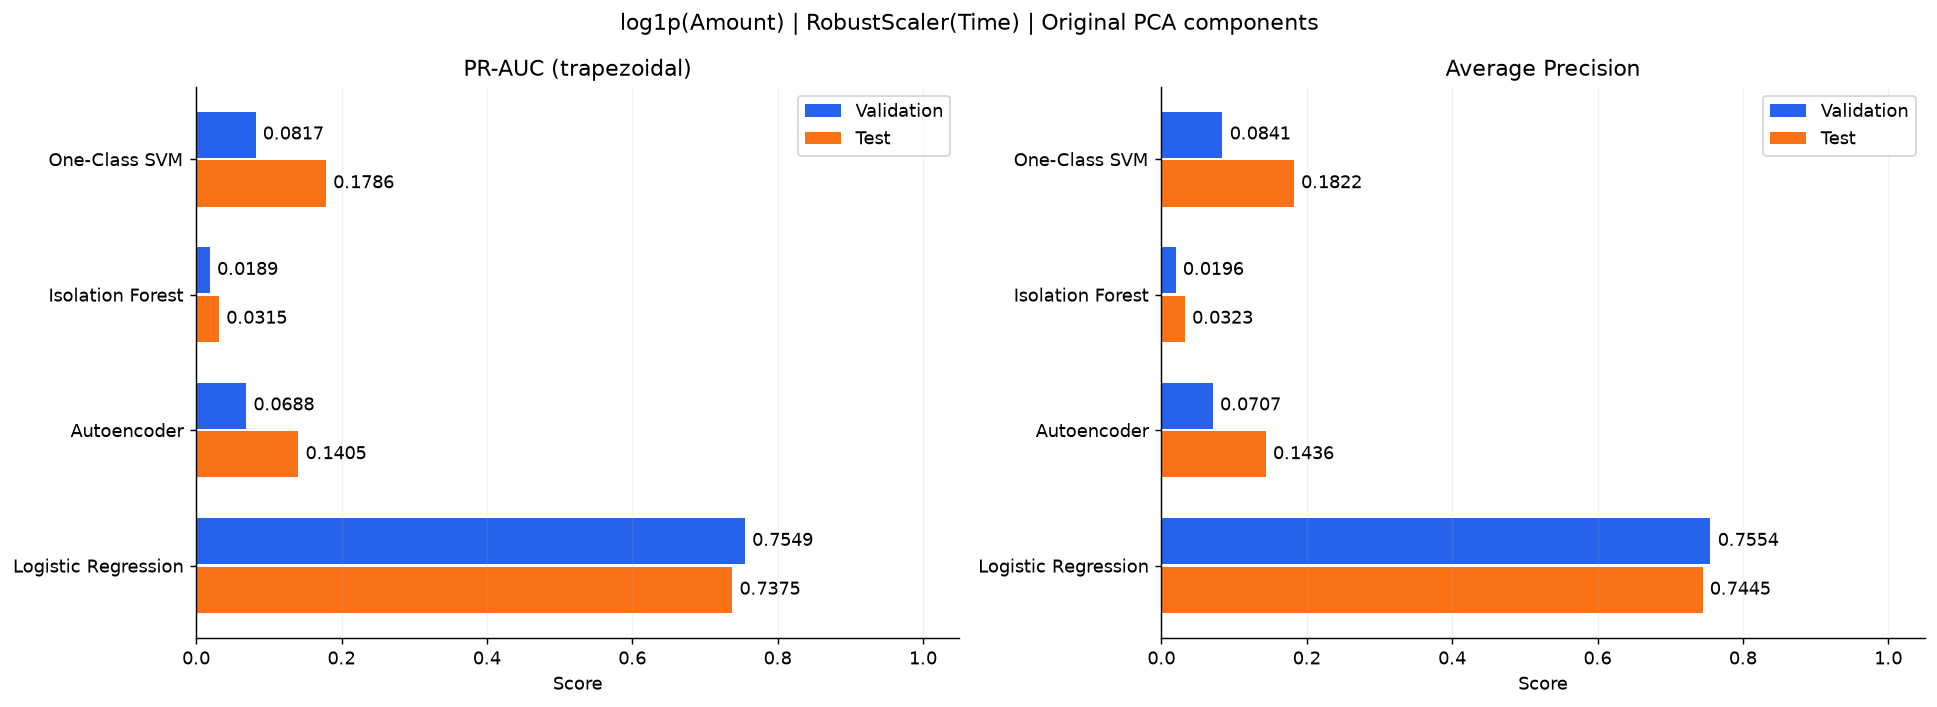

In [10]:
fig, axes = plt.subplots(1, 2, figsize = (15, 5.5))
positions = np.arange(len(results))

for ax, metric, title in [
    (axes[0], "PR_AUC", "PR-AUC (trapezoidal)"),
    (axes[1], "AP", "Average Precision"),
]:
    valid_bars = ax.barh(
        positions - 0.18,
        results["valid_" + metric],
        height = 0.34,
        label = "Validation",
        color = "#2563eb",
    )

    test_bars = ax.barh(
        positions + 0.18,
        results["test_" + metric],
        height = 0.34,
        label = "Test",
        color = "#f97316",
    )

    ax.bar_label(valid_bars, fmt = "%.4f", padding = 4)
    ax.bar_label(test_bars, fmt = "%.4f", padding = 4)
    ax.set_yticks(positions, results["model"])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)
    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.grid(axis = "x", alpha = 0.15)
    ax.legend(loc = "upper right")

fig.suptitle("log1p(Amount) | RobustScaler(Time) | Original PCA components")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "metric_comparison.png", dpi = 170, bbox_inches = "tight")
plt.show()

### Precision-Recall 곡선

- 가로축 Recall, 세로축 Precision. 사기 Class=1을 기준으로 그림.
- 선은 사다리꼴 PR-AUC 계산과 동일하게 점 사이를 직선으로 연결함.
- 점선은 각 평가 구간의 사기 비율임.

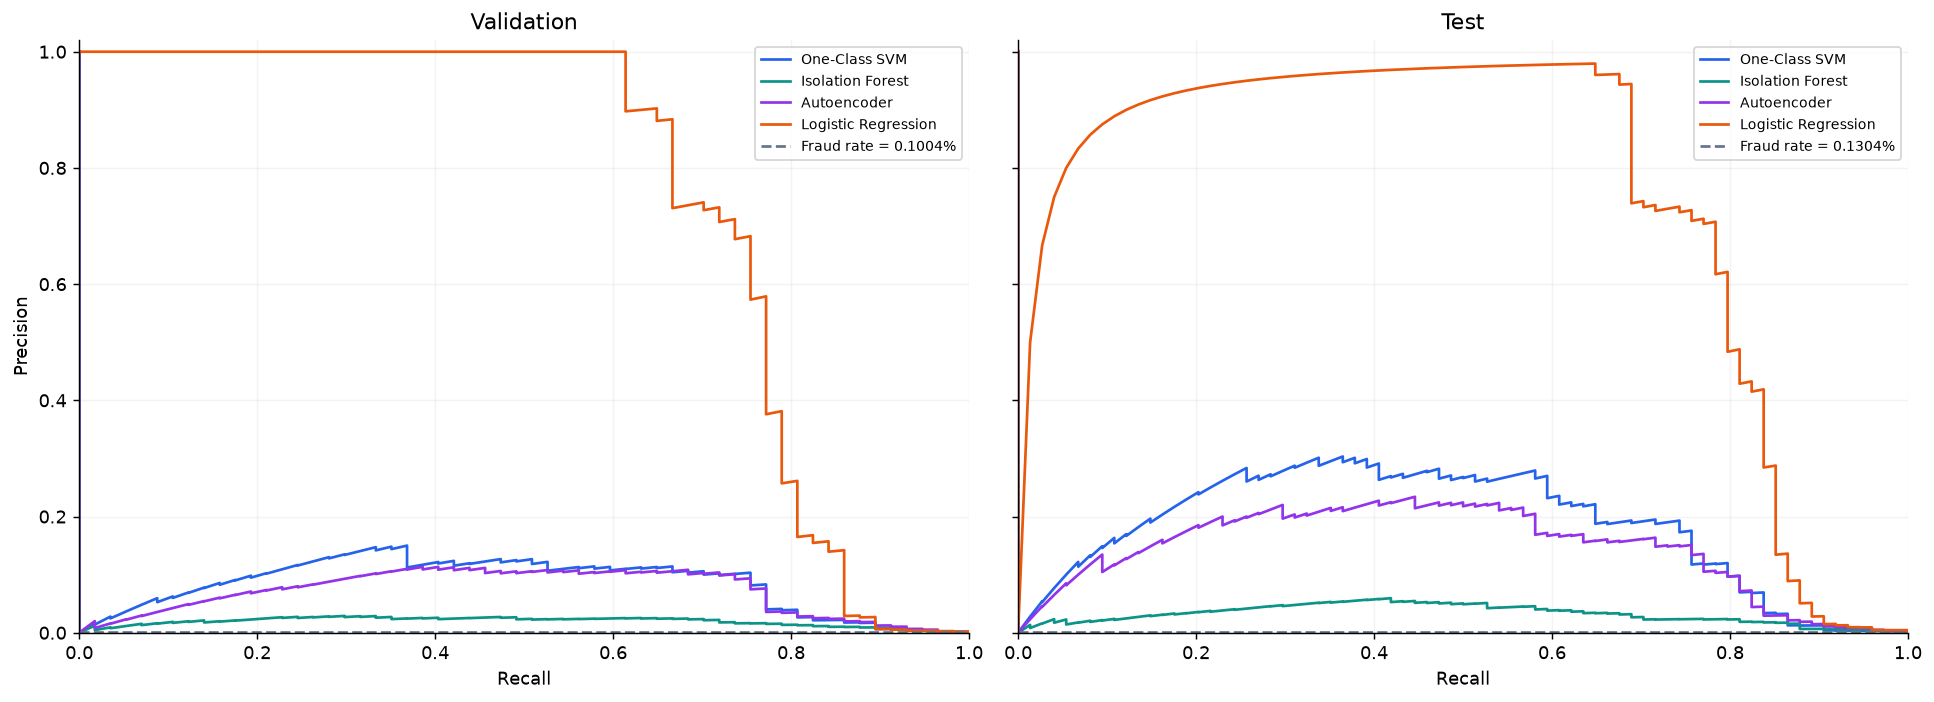

In [11]:
fig, axes = plt.subplots(1, 2, figsize = (15, 5.5), sharex = True, sharey = True)
colors = ["#2563eb", "#0d9488", "#9333ea", "#ea580c"]

for ax, title, target, score_dict in [
    (axes[0], "Validation", y_valid, validation_scores),
    (axes[1], "Test", y_test, test_scores),
]:
    for color, (exp_id, scores) in zip(colors, score_dict.items()):
        precision, recall, _ = precision_recall_curve(target, scores, pos_label = 1)

        ax.plot(
            recall,
            precision,
            color = color,
            linewidth = 1.5,
            label = model_names[exp_id],
        )

    ax.axhline(
        target.mean(),
        color = "#64748b",
        linestyle = "--",
        label = f"Fraud rate = {target.mean():.4%}",
    )

    ax.set(title = title, xlabel = "Recall", xlim = (0, 1), ylim = (0, 1.02))
    ax.grid(alpha = 0.15)
    ax.legend(fontsize = 8, loc = "upper right")

axes[0].set_ylabel("Precision")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "precision_recall_curves.png", dpi = 170, bbox_inches = "tight")
plt.show()

## Conclusion

| 모델 | 학습 데이터 | 검증 PR-AUC | 테스트 PR-AUC | 검증 AP | 테스트 AP |
|---|---|---:|---:|---:|---:|
| One-Class SVM | 정상 | 0.081741 | 0.178556 | 0.084073 | 0.182208 |
| Isolation Forest | 정상 | 0.018873 | 0.031472 | 0.019560 | 0.032312 |
| Autoencoder | 정상 | 0.068811 | 0.140527 | 0.070681 | 0.143580 |
| Logistic Regression | 정상 + 사기 | 0.754914 | 0.737503 | 0.755419 | 0.744479 |

- One-Class SVM의 테스트 PR-AUC는 **0.178556**, AP는 **0.182208**로 나타남.
- 이 결과는 Amount 로그 변환만 적용, Time만 RobustScaler 적용, PCA 변수 유지 조건에서 얻은 결과임.
- 정상 단독 세 모델은 같은 5,000건을 사용하고, 로지스틱 회귀는 정상과 사기를 포함한 학습 구간 전체를 사용함.
- 모델 간 차이에는 학습 방법, 사기 정답 활용 여부와 학습 표본 수의 차이가 함께 포함됨.
- 검증 사기 57건 / 테스트 사기 74건, 단일 분할 및 단일 난수 시드 결과이므로 모델의 일반적인 성능 상한으로 해석하지 않음.

### 결과 파일

- [평가 결과표](../results/model_comparison/model_results.csv)
- [지표 비교 그래프](../results/model_comparison/metric_comparison.png)
- [PR 곡선](../results/model_comparison/precision_recall_curves.png)
- ?? ?? ????? One-Class SVM? ?? / ???? ? ?? ?? Autoencoder? Isolation Forest?? ?? ?? ???.
- ???? ??? ??? PR-AUC? 0.737503, AP? 0.744479? ? ?? ? ?? ??.
- ?? ????? ? ?? ?? ?? ??? ???? ???.
